In [1]:
# !pip install natsort
# !pip install scipy
# !pip install natsort
# !pip install ipywidgets

import cv2
import pickle
import numpy as np
import os
import matplotlib.pyplot as plt
import re

import torch

import numpy as np
# import ipywidgets as widgets
from IPython.display import display, clear_output
from natsort import natsorted
import os
import scipy
from scipy.sparse import spdiags
from scipy.signal import butter
import math
from scipy import linalg
from scipy import signal
from scipy import sparse

# Helper Functions

In [2]:
# HELPER FUNCTIONS

def _reform_data_from_dict(data, flatten=True):
    """Helper func for calculate metrics: reformat predictions and labels from dicts. """
    sort_data = sorted(data.items(), key=lambda x: x[0])
    sort_data = [i[1] for i in sort_data]
    sort_data = torch.cat(sort_data, dim=0)

    if flatten:
        sort_data = np.reshape(sort_data.cpu(), (-1))
    else:
        sort_data = np.array(sort_data.cpu())

    return sort_data

def _process_signal(signal, fs=30, diff_flag=True):
    # Detrend and filter
    use_bandpass = True
    if diff_flag:  # if the predictions and labels are 1st derivative of PPG signal.
        gt_bvp = _detrend(np.cumsum(signal), 100)
    else:
        gt_bvp = _detrend(signal, 100)
    if use_bandpass:
        # bandpass filter between [0.75, 2.5] Hz
        # equals [45, 150] beats per min
        [b, a] = butter(1, [0.75 / fs * 2, 2.5 / fs * 2], btype='bandpass')
        signal = scipy.signal.filtfilt(b, a, np.double(signal))
    return signal

def _detrend(input_signal, lambda_value):
    """Detrend PPG signal."""
    signal_length = input_signal.shape[0]
    # observation matrix
    H = np.identity(signal_length)
    ones = np.ones(signal_length)
    minus_twos = -2 * np.ones(signal_length)
    diags_data = np.array([ones, minus_twos, ones])
    diags_index = np.array([0, 1, 2])
    D = spdiags(diags_data, diags_index,
                (signal_length - 2), signal_length).toarray()
    detrended_signal = np.dot(
        (H - np.linalg.inv(H + (lambda_value ** 2) * np.dot(D.T, D))), input_signal)
    return detrended_signal


In [42]:
# data_out_path = "runs/PhysMamba_20260128_121927/outputs/MMPD_MMPD_PhysMamba_Epoch26_MMPD_outputs.pickle"
# data_out_path = "runs/PhysMamba_20260128_123104_UBFC_0.45/outputs/UBFC_UBFC_UBFC_PhysMamba_Epoch29_UBFC-rPPG_outputs.pickle"
data_out_path =  "runs/PhysMamba_20260128_115735_0.24_PURE/outputs/PURE_PURE_PURE_PhysMamba_Epoch29_PURE_outputs.pickle"   #best 1
# data_out_path =  "/raid/muhammadu/MC_drop/rPPG-Toolbox/model_outputs/PURE_PURE_UBFC_deepphys_outputs.pickle"   #"./sample_output.pickle"  # Output Data Path 


In [43]:
# Read in data and list subjects
with open(data_out_path, 'rb') as f:
    data = pickle.load(f)
    
# List of all video trials
trial_list = list(data['predictions'].keys())
print('Num Trials', len(trial_list))

Num Trials 24


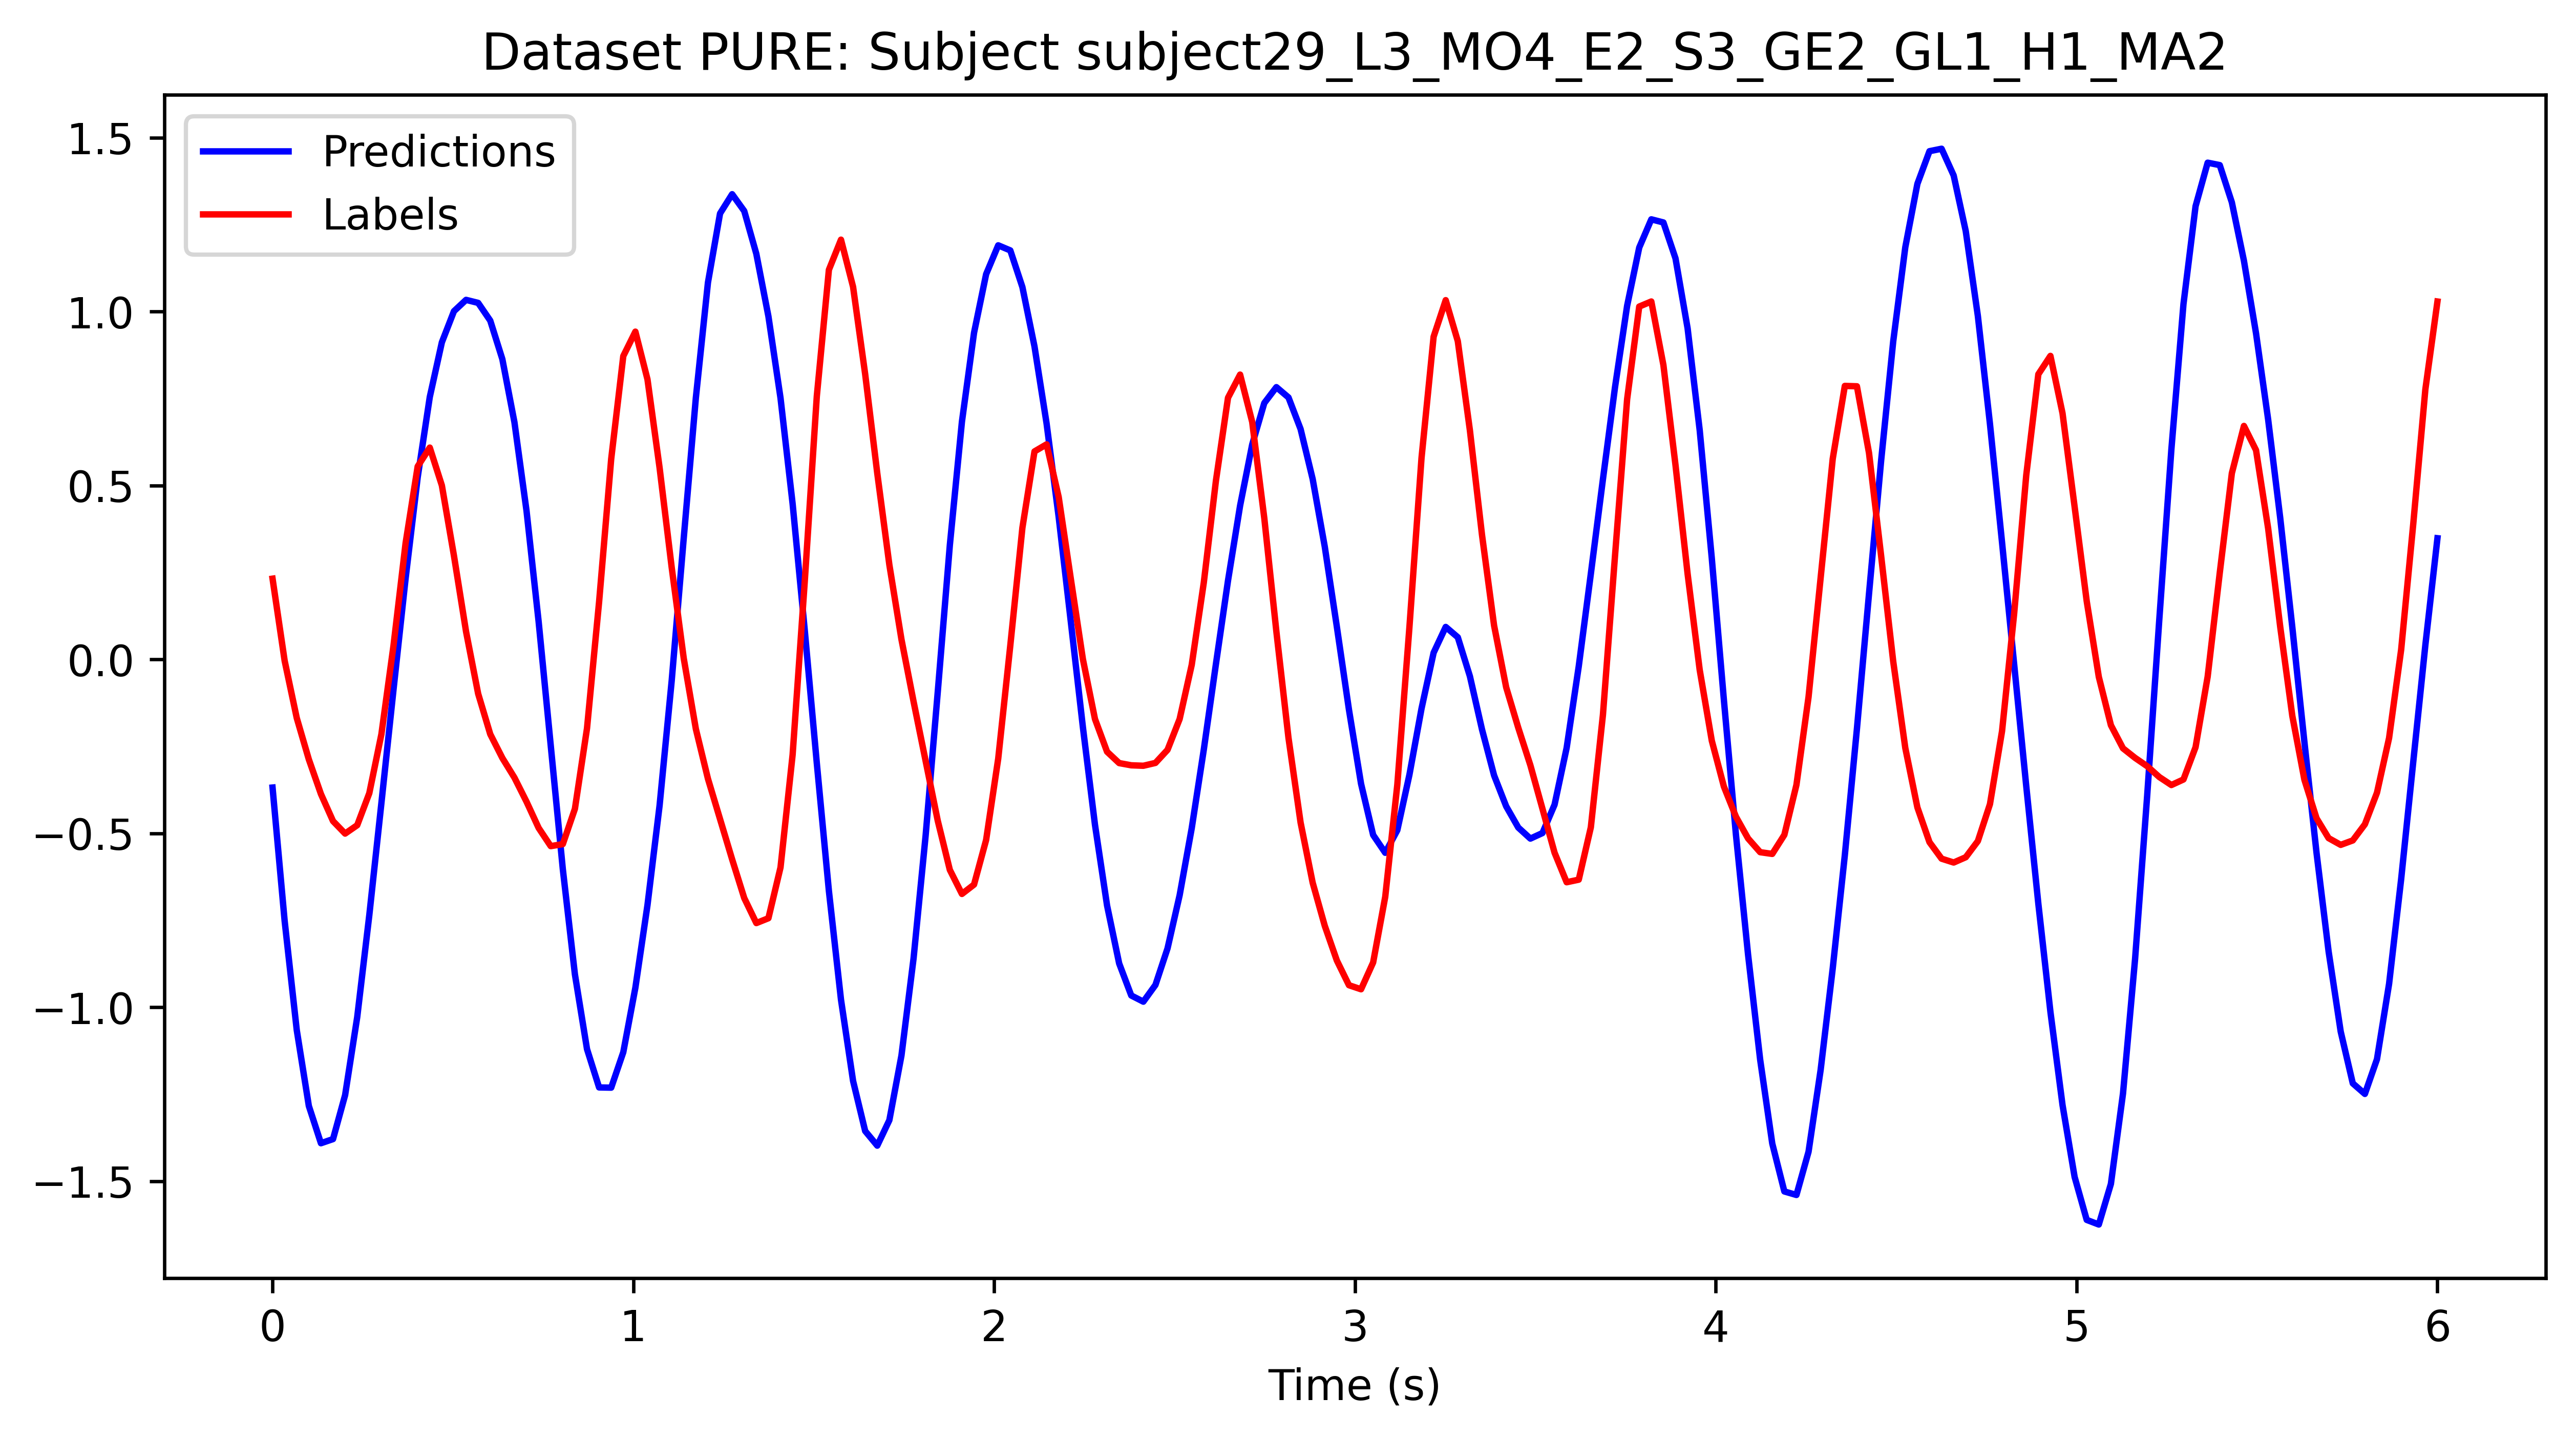

In [5]:
trial_idx = 54
chunk_size = 180 # size of chunk to visualize: -1 will plot the entire signal
chunk_num = 3

# Reform label and prediction vectors from multiple trial chunks
prediction = np.array(_reform_data_from_dict(data['predictions'][trial_list[trial_idx]]))
label = np.array(_reform_data_from_dict(data['labels'][trial_list[trial_idx]]))

# Read in meta-data from pickle file
fs = data['fs'] # Video Frame Rate
label_type = data['label_type'] # PPG Signal Transformation: `DiffNormalized` or `Standardized`
diff_flag = (label_type == 'DiffNormalized')

if chunk_size == -1:
    chunk_size = len(prediction)
# chunk_num = 1
#  MMPD 3, bad
# Process label and prediction signals
prediction = _process_signal(prediction, fs, diff_flag=diff_flag)
label = _process_signal(label, fs, diff_flag=diff_flag)
start = (chunk_num)*chunk_size
stop = (chunk_num+1)*chunk_size
samples = stop - start
x_time = np.linspace(0, samples/fs, num=samples)

plt.figure(figsize=(10,5), dpi=600)
plt.plot(x_time, prediction[start:stop], color='b')
plt.plot(x_time, label[start:stop], color='r')
# plt.title('Trial: ' + trial_list[trial_idx])
plt.title('Dataset PURE: Subject ' + trial_list[trial_idx])
plt.legend(['Predictions', 'Labels'])
plt.xlabel('Time (s)');

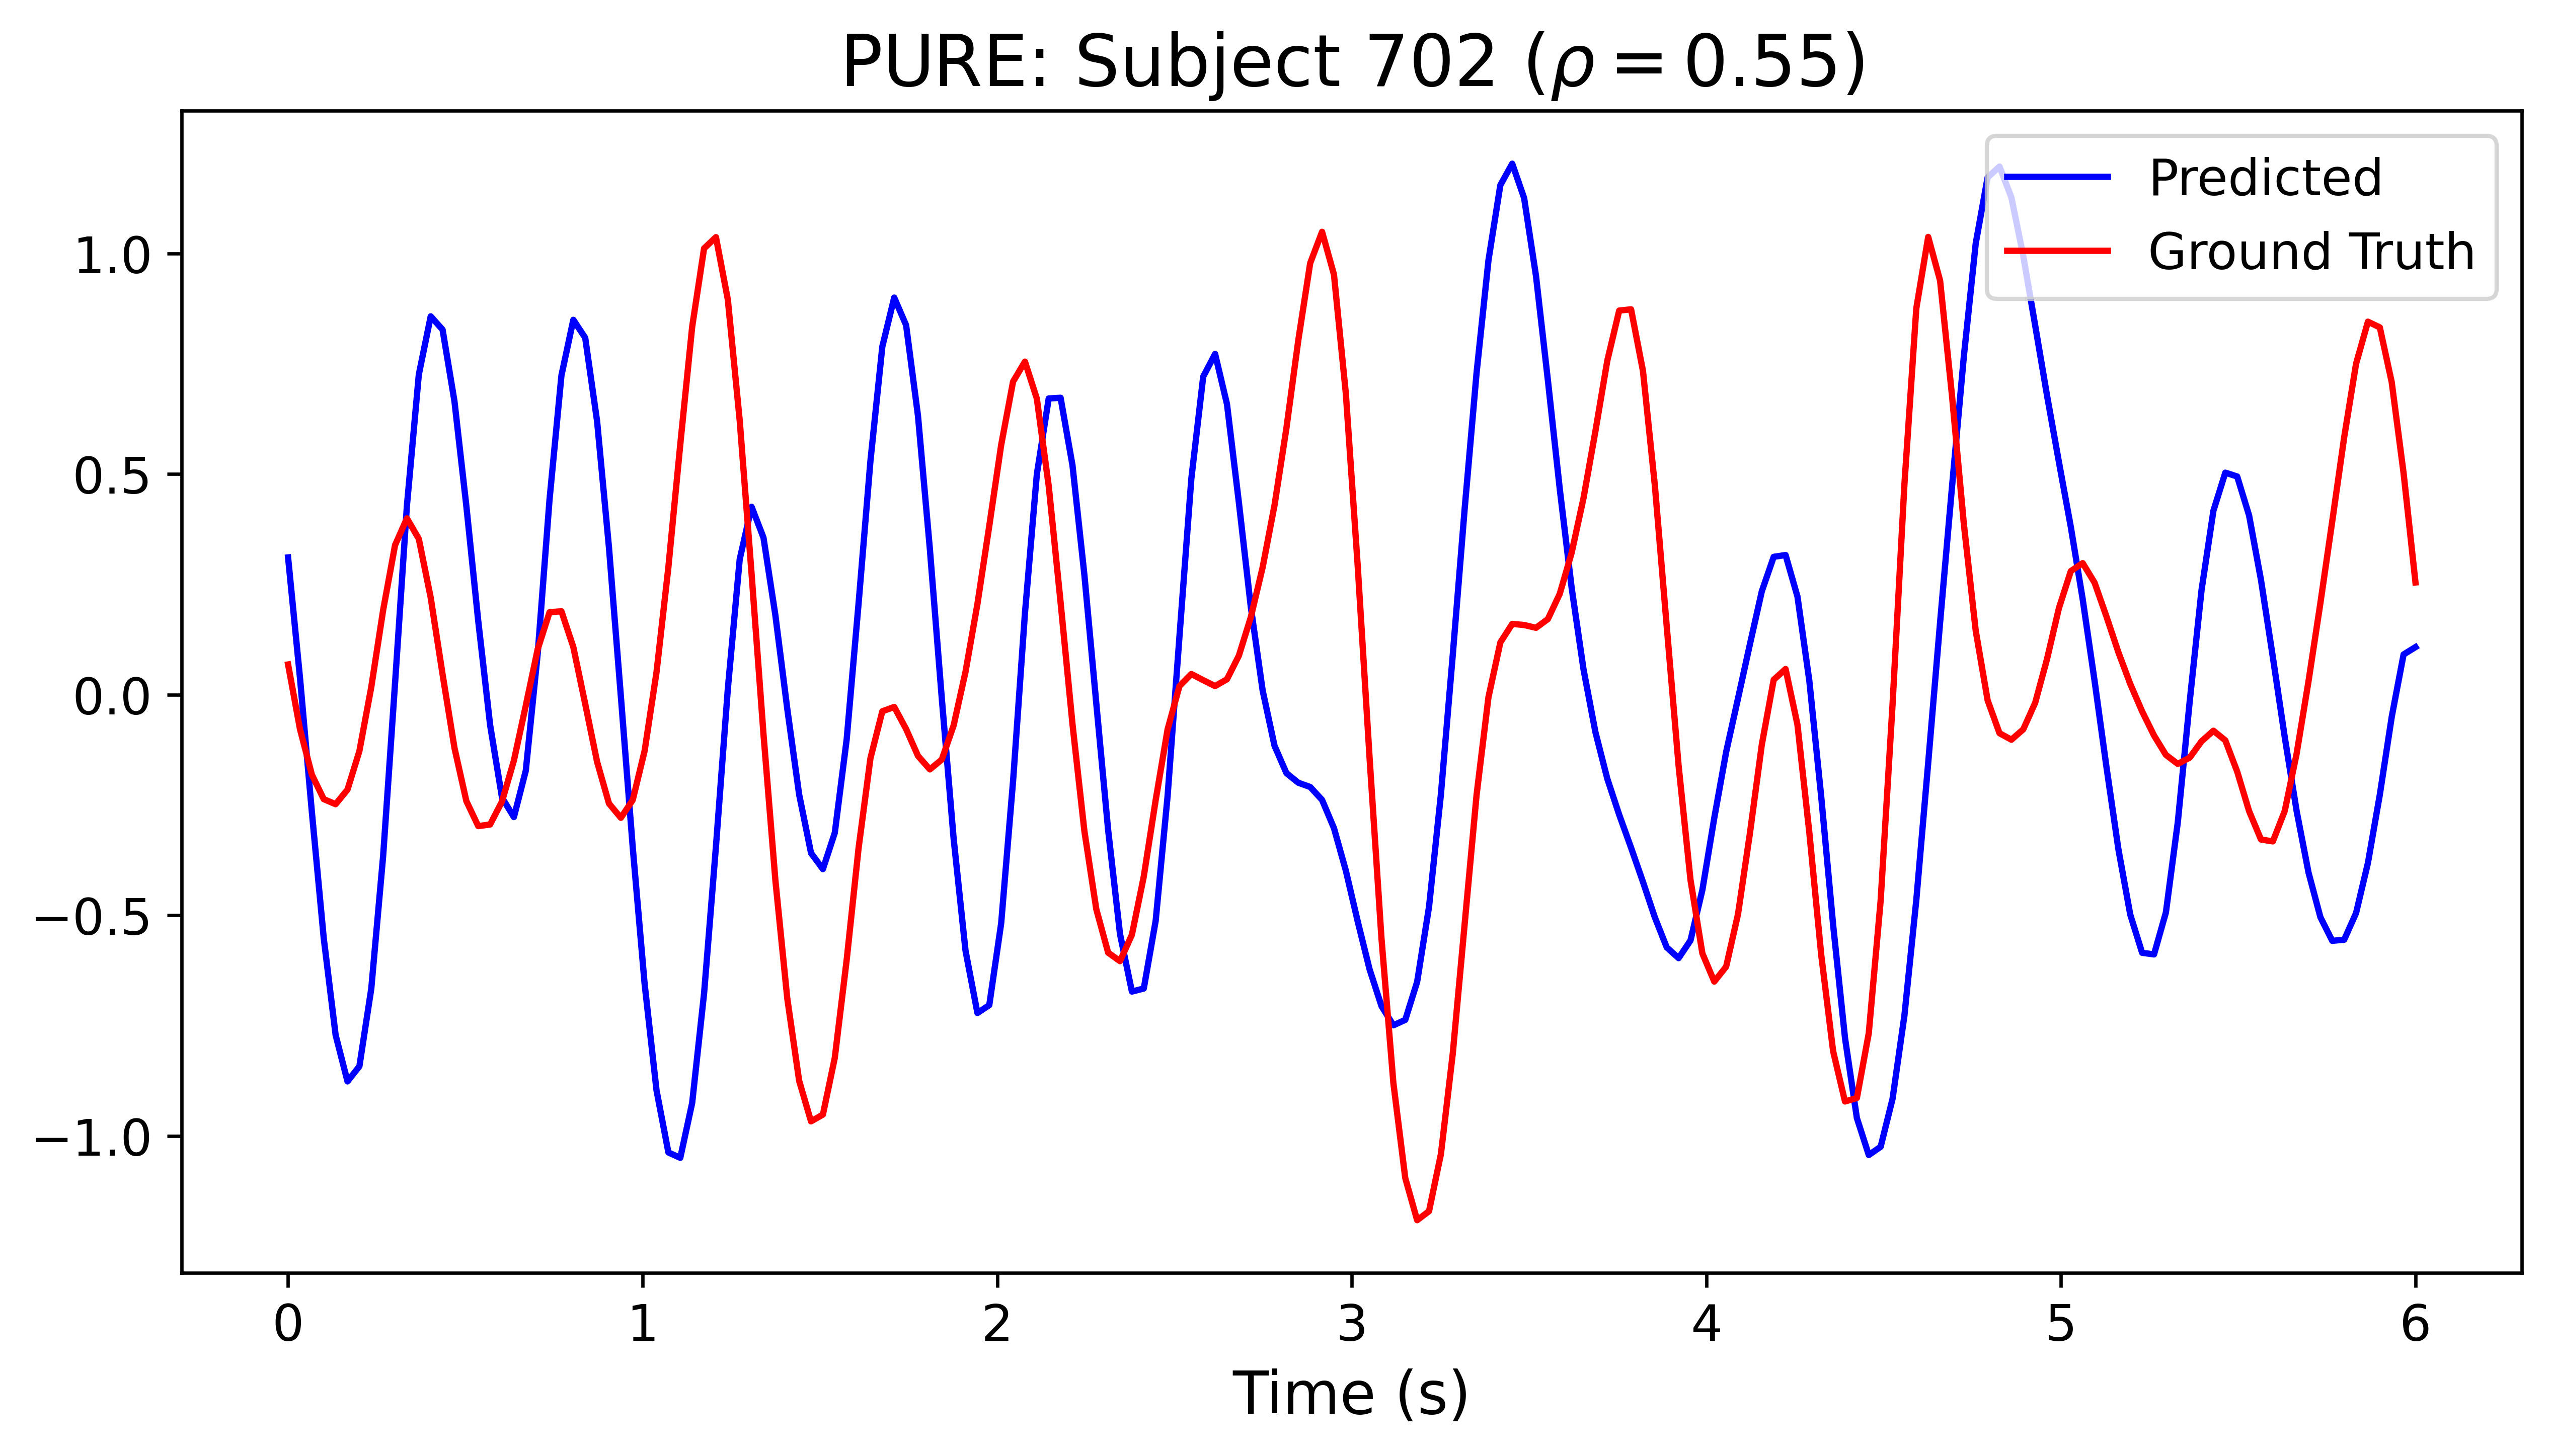

In [54]:
# worse alignment 136, 1, 2
trial_idx = 7
chunk_size = 180 # size of chunk to visualize: -1 will plot the entire signal
chunk_num = 4

# Reform label and prediction vectors from multiple trial chunks
prediction = np.array(_reform_data_from_dict(data['predictions'][trial_list[trial_idx]]))
label = np.array(_reform_data_from_dict(data['labels'][trial_list[trial_idx]]))

# Read in meta-data from pickle file
fs = data['fs'] # Video Frame Rate
label_type = data['label_type'] # PPG Signal Transformation: `DiffNormalized` or `Standardized`
diff_flag = (label_type == 'DiffNormalized')

if chunk_size == -1:
    chunk_size = len(prediction)
# chunk_num = 1
#  MMPD best:1, 2 ,worse 54, 5, 
# PURE best:14, 4, worse:
# UBFC best:6,2, worse: 7, 4
# Process label and prediction signals
prediction = _process_signal(prediction, fs, diff_flag=diff_flag)
label = _process_signal(label, fs, diff_flag=diff_flag)
start = (chunk_num)*chunk_size
stop = (chunk_num+1)*chunk_size
samples = stop - start
x_time = np.linspace(0, samples/fs, num=samples)

import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 12,        # base size
    'axes.titlesize': 17,   # title
    'axes.labelsize': 14,   # x/y labels
    'legend.fontsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12
})

plt.figure(figsize=(10,5), dpi=600)
plt.plot(x_time, prediction[start:stop], color='b')
plt.plot(x_time, label[start:stop], color='r')
# plt.title('Trial: ' + trial_list[trial_idx])
plt.title('PURE: Subject 702'+ r' ($\rho = 0.55$)')
plt.legend(['Predicted', 'Ground Truth'], loc='upper right')
plt.xlabel('Time (s)');

In [ ]:
import pandas as pd
# Find worst-aligned 5 trials across all trial_idx (0..len(trial_list)-1)
def max_pearson_with_lag(x, y, max_lag=90):
    """Return max Pearson correlation and lag (in samples)."""
    n = min(len(x), len(y))
    if n < 3:
        return np.nan, 0
    x = x[:n]
    y = y[:n]

    best_r = -np.inf
    best_lag = 0
    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            xx, yy = x[:lag], y[-lag:]
        elif lag > 0:
            xx, yy = x[lag:], y[:-lag]
        else:
            xx, yy = x, y

        if len(xx) < 3:
            continue
        if np.std(xx) < 1e-12 or np.std(yy) < 1e-12:
            continue

        r = np.corrcoef(xx, yy)[0, 1]
        if np.isfinite(r) and r > best_r:
            best_r = r
            best_lag = lag

    if not np.isfinite(best_r):
        return np.nan, 0
    return float(best_r), int(best_lag)

rows = []
fs = float(data['fs'])
label_type = data.get('label_type', 'Standardized')
diff_flag = (label_type == 'DiffNormalized')

# About 3 seconds lag search window (adjust if needed)
max_lag_samples = int(3 * fs)

for idx, trial_name in enumerate(trial_list):
    pred = np.array(_reform_data_from_dict(data['predictions'][trial_name]))
    gt = np.array(_reform_data_from_dict(data['labels'][trial_name]))

    pred = _process_signal(pred, fs, diff_flag=diff_flag)
    gt = _process_signal(gt, fs, diff_flag=diff_flag)

    n = min(len(pred), len(gt))
    if n < 3:
        continue
    pred = pred[:n]
    gt = gt[:n]

    # zero-lag correlation
    if np.std(pred) < 1e-12 or np.std(gt) < 1e-12:
        r0 = np.nan
    else:
        r0 = float(np.corrcoef(pred, gt)[0, 1])

    # lag-aware alignment quality
    rmax, best_lag = max_pearson_with_lag(pred, gt, max_lag=max_lag_samples)

    rows.append({
        'trial_idx': idx,
        'trial_name': trial_name,
        'num_samples': n,
        'pearson_zero_lag': r0,
        'pearson_max_lag': rmax,
        'best_lag_samples': best_lag,
        'best_lag_seconds': best_lag / fs
    })

alignment_df = pd.DataFrame(rows)

# Worst alignment = lowest lag-aware Pearson correlation
worst5 = alignment_df.sort_values('pearson_max_lag', ascending=True).head(5)
print('Worst aligned 5 trial_idx (based on lowest pearson_max_lag):')
display(worst5[['trial_idx', 'trial_name', 'pearson_zero_lag', 'pearson_max_lag', 'best_lag_samples', 'best_lag_seconds']])

# Optional: if you prefer strict zero-lag mismatch, use this instead:
# display(alignment_df.sort_values('pearson_zero_lag', ascending=True).head(5)[['trial_idx','trial_name','pearson_zero_lag']])

Worst aligned 5 trial_idx (based on lowest pearson_max_lag):


,trial_idx,trial_name,pearson_zero_lag,pearson_max_lag,best_lag_samples,best_lag_seconds
54,54,subject29_L3_MO4_E2_S3_GE2_GL1_H1_MA2,0.053385,0.110869,37,1.233333
82,82,subject31_L1_MO2_E2_S5_GE1_GL2_H2_MA2,0.024561,0.113086,54,1.800000
59,59,subject29_L4_MO4_E2_S3_GE2_GL1_H1_MA2,0.075845,0.118700,-53,-1.766667
64,64,subject30_L1_MO4_E2_S6_GE1_GL2_H2_MA2,0.044602,0.123550,-61,-2.033333
79,79,subject30_L4_MO4_E2_S6_GE1_GL2_H2_MA2,-0.008487,0.124739,90,3.000000


In [199]:
# Best aligned 5 trials (highest correlation with GT)
if 'alignment_df' not in globals() or alignment_df.empty:
    print("alignment_df is missing or empty. Run the previous alignment cell first.")
else:
    # Best by lag-aware Pearson correlation
    best5 = alignment_df.sort_values('pearson_max_lag', ascending=False).head(5)
    print('Best aligned 5 trial_idx (based on highest pearson_max_lag):')
    display(best5[['trial_idx', 'trial_name', 'num_samples','pearson_zero_lag', 'pearson_max_lag', 'best_lag_samples', 'best_lag_seconds']])

    # Optional: strict no-shift best correlations
    print('\nBest aligned 5 trial_idx (strict zero-lag Pearson):')
    display(
        alignment_df.sort_values('pearson_zero_lag', ascending=False).head(5)[
            ['trial_idx', 'trial_name', 'pearson_zero_lag', 'pearson_max_lag', 'best_lag_seconds']
        ]
    )

Best aligned 5 trial_idx (based on highest pearson_max_lag):


,trial_idx,trial_name,num_samples,pearson_zero_lag,pearson_max_lag,best_lag_samples,best_lag_seconds
106,106,subject32_L2_MO1_E2_S3_GE2_GL2_H2_MA2,1760,0.936470,0.959152,-1,-0.033333
111,111,subject32_L3_MO1_E2_S3_GE2_GL2_H2_MA2,1760,0.944875,0.958298,-1,-0.033333
121,121,subject33_L1_MO3_E2_S3_GE2_GL2_H2_MA2,1760,0.956248,0.956248,0,0.000000
105,105,subject32_L2_MO1_E1_S3_GE2_GL2_H2_MA2,1760,0.806059,0.956081,-2,-0.066667
13,13,subject27_L3_MO3_E2_S3_GE2_GL2_H2_MA1,1760,0.947639,0.953990,-1,-0.033333



Best aligned 5 trial_idx (strict zero-lag Pearson):


,trial_idx,trial_name,pearson_zero_lag,pearson_max_lag,best_lag_seconds
121,121,subject33_L1_MO3_E2_S3_GE2_GL2_H2_MA2,0.956248,0.956248,0.000000
103,103,subject32_L1_MO3_E2_S3_GE2_GL2_H2_MA2,0.952525,0.952525,0.000000
133,133,subject33_L4_MO1_E2_S3_GE2_GL2_H2_MA2,0.952201,0.952201,0.000000
107,107,subject32_L2_MO2_E2_S3_GE2_GL2_H2_MA2,0.949744,0.952008,0.766667
13,13,subject27_L3_MO3_E2_S3_GE2_GL2_H2_MA1,0.947639,0.953990,-0.033333
